## M1a: corrected comparison ($\alpha=0.5$)

Paper figures 1. Saved results are shown by default; enable the switches below to recompute.

In [1]:
from pathlib import Path
import os
if not Path("WERM").is_dir() and Path("../WERM").is_dir():
    os.chdir("..")
assert Path("WERM").is_dir(), "Open this notebook from the repository root."
from paper_support import show_panels
RUN_EXPERIMENTS = False
REGENERATE_FIGURES = False
REGENERATE_FIGURES = REGENERATE_FIGURES or RUN_EXPERIMENTS

if REGENERATE_FIGURES:
    import numpy as np, pickle, time, logging
    import matplotlib.pyplot as plt
    from IPython.display import display
    main_logger = logging.getLogger("paper")
    Path("figures").mkdir(exist_ok=True)


In [2]:
if RUN_EXPERIMENTS:
    import os
    import sys
    _active_env_bin = os.path.dirname(sys.executable)
    os.environ['PATH'] = _active_env_bin + os.pathsep + os.environ.get('PATH', '')
    _active_r_home = os.path.join(sys.prefix, 'lib', 'R')
    if os.path.isdir(_active_r_home):
        os.environ['R_HOME'] = _active_r_home
    from WERM.signal_priors import SparseGaussianSignal, SparseDiffSignal
    import WERM.model
    import WERM.performance_measures
    import importlib
    import WERM.comparison
    importlib.reload(WERM.comparison)
    import WERM.estimators
    from WERM.config import η_to_ψ
    import numpy as np
    import jax.numpy as jnp
    import jax
    jax.config.update('jax_enable_x64', True)
    import numpy.random as nprandom
    import matplotlib.pyplot as plt
    plt.switch_backend('module://matplotlib_inline.backend_inline')
    from functools import partial
    from tqdm.auto import tqdm
    from WERM.experiment_utils import data_hash as _data_hash, evaluate_changepoints as _evaluate_changepoints, summarize_setting as _summarize_setting, trial_rng as _trial_rng, weighted_erm_joint_cv as _weighted_erm_joint_cv
    import time
    from joblib import Parallel, delayed
    import sys
    import pickle
    import os
    os.environ['JAX_ENABLE_X64'] = 'True'
    random_seed = 42

    def run_single_trial(params, p, L, noise_std, fractional_chgpt_locations, M, gamma_candidates, method_configs):
        """
        Executes a single simulation trial for a given delta, running multiple methods.
        This function is designed to be called in parallel by joblib.
        """
        (i, delta, j) = params
        rng = _trial_rng('M1a-final', i, j)
        n = int(delta * p)
        true_chgpt_locations_fn = lambda n_len: (n_len * fractional_chgpt_locations).astype(int)
        kappa = 1.0
        alpha = 0.5
        sigma_l_arr = kappa * np.sqrt(delta) * np.ones(L)
        signal_prior = SparseGaussianSignal(alpha, delta, sigma_l_arr)
        B̃ = signal_prior.sample(p, rng=rng)
        X = rng.normal(0, np.sqrt(1 / n), (n, p))
        ε = rng.normal(0.0, noise_std, size=n)
        X = X @ np.linalg.cholesky(Sigma).T
        true_chgpts = true_chgpt_locations_fn(n)
        C_true = η_to_ψ(true_chgpts, n) if true_chgpts.size > 0 else np.zeros(n).astype(int)
        X_scaled = X * np.sqrt(n)
        B̃_scaled = B̃ / np.sqrt(n)
        Θ = X_scaled @ B̃_scaled
        y = jax.vmap(WERM.model.q_linear_model, in_axes=(0, 0, 0))(Θ, C_true, ε)
        y_standardized = np.asarray(y / (alpha * kappa ** 2 + noise_std ** 2))
        trial_results = {'data_hash': _data_hash(X, y)}
        methods_status = {method_name: False for method_name in method_configs.keys()}
        for (method_name, method_func_info) in method_configs.items():
            try:
                method_start = time.time()
                cp = np.array([])
                if method_name == 'McScan':
                    cp = np.asarray(WERM.comparison.run_mcscan(np.array(X_scaled), y_standardized, num_chgpts=L - 1))
                    cp = np.array([c for c in cp if c != -1], dtype=int)
                elif method_name == 'MOSEG':
                    res = WERM.comparison.MOSEG(np.array(X_scaled), y_standardized, num_chgpts=L - 1, ms=False)
                    cp = res[2]
                    if cp is WERM.comparison.rpy2.rinterface.NULL:
                        cp = np.array([], dtype=int)
                    else:
                        cp = np.array([c for c in cp if c != -1], dtype=int)
                elif method_name == 'WERM-unp':
                    cp = WERM.estimators.weighted_erm(X=X, y=y, M=M, L=L, Delta_n=1, gamma=0.0, L_is_upper_bound=False, return_B_hat=False, brute_force=False)
                else:
                    continue
                method_time = time.time() - method_start
                evaluation = _evaluate_changepoints(cp, true_chgpts, n)
                raw_cp = evaluation['raw_cp']
                trial_results[f'runtime_{method_name}'] = method_time
                trial_results[f'raw_cp_{method_name}'] = None if raw_cp is None else raw_cp.copy()
                trial_results[f'status_{method_name}'] = evaluation['status']
                haus_value = evaluation['haus']
                if evaluation['status'] == 'empty_estimate':
                    haus_value = np.nan
                trial_results[f'haus_{method_name}'] = haus_value
                trial_results[f'size_{method_name}'] = evaluation['size']
                trial_results[f'chgpts_{method_name}'] = np.array([]) if raw_cp is None else raw_cp.copy()
                methods_status[method_name] = evaluation['status'] != 'not_applicable'
            except Exception as e:
                raise
        trial_results['n'] = n
        trial_results['true_chgpts'] = true_chgpts.copy()
        trial_results['fractional_true_chgpts'] = fractional_chgpt_locations.copy()
        trial_results['methods_status'] = methods_status
        return (i, j, trial_results)
    p = 200
    L = 3
    noise_std = np.sqrt(0.6)
    delta_list = np.arange(1.0, 7.0, 1.0)
    num_trials = 100
    fractional_chgpt_locations = np.array([0.4, 0.7])
    n_jobs = max(1, min(int(os.environ.get('WERM_N_JOBS', '36')), 36))
    r = 0.2
    Sigma = np.eye(p)
    for i_cov in range(p):
        for j_cov in range(p):
            if i_cov != j_cov:
                Sigma[i_cov, j_cov] = np.power(r, abs(i_cov - j_cov))
    FINAL_METHOD_NAMES = ['McScan', 'MOSEG', 'WERM-unp']
    method_catalog = {'McScan': {'name': 'McScan', 'label': 'McScan', 'color': '#AA3377', 'marker': 'o', 'linestyle': '--'}, 'MOSEG': {'name': 'MOSEG', 'label': 'MOSEG', 'color': '#228833', 'marker': 's', 'linestyle': '-.'}, 'WERM-unp': {'name': 'WERM-unp', 'label': '\\textbf{WERM}', 'color': 'black', 'marker': 'D', 'linestyle': '-'}}
    methods_to_evaluate = [method_catalog[name].copy() for name in FINAL_METHOD_NAMES]
    method_configs = {method['name']: method for method in methods_to_evaluate}
    method_names_list = [m['name'] for m in methods_to_evaluate]
    results = {'successful_trials': {method['name']: np.zeros(len(delta_list), dtype=int) for method in methods_to_evaluate}, 'true_chgpts': [], 'n_values': [], 'delta_values': []}
    for method in methods_to_evaluate:
        method_name = method['name']
        results[f'haus_{method_name}'] = np.full((len(delta_list), num_trials), np.nan)
        results[f'size_{method_name}'] = np.full((len(delta_list), num_trials), np.nan)
        results[f'runtime_{method_name}'] = np.full((len(delta_list), num_trials), np.nan)
        results[f'chgpts_{method_name}'] = []
    M = lambda u, v: jnp.power(u - v, 2)
    M_scorer = lambda u, v: jnp.abs(u - v)
    gamma_candidates = np.logspace(-1, 2, 5)
    paper_setting_indices = [1, 2, 3, 4, 5]
    tasks = [(i, delta, j) for (i, delta) in enumerate(delta_list) if i in paper_setting_indices for j in range(num_trials)]
    try:
        parallel_results = Parallel(n_jobs=n_jobs, verbose=0)((delayed(run_single_trial)(params=task, p=p, L=L, noise_std=noise_std, fractional_chgpt_locations=fractional_chgpt_locations, M=M, gamma_candidates=gamma_candidates, method_configs=method_configs) for task in tqdm(tasks, desc='Running simulation trials', ncols=100)))
    except Exception as e:
        raise
    for (result_idx, (i, j, trial_result)) in enumerate(parallel_results):
        for method_obj in methods_to_evaluate:
            method_name = method_obj['name']
            if trial_result['methods_status'][method_name]:
                results[f'haus_{method_name}'][i, j] = trial_result[f'haus_{method_name}']
                results[f'size_{method_name}'][i, j] = trial_result[f'size_{method_name}']
                results[f'runtime_{method_name}'][i, j] = trial_result[f'runtime_{method_name}']
                results['successful_trials'][method_name][i] += 1
            results[f'chgpts_{method_name}'].append((i, trial_result[f'chgpts_{method_name}']))
        results['true_chgpts'].append((i, trial_result['true_chgpts']))
        results['n_values'].append((i, trial_result['n']))
        results['delta_values'].append((i, delta_list[i]))
    results['trial_records'] = parallel_results
    results['summaries'] = []
    for (setting_idx, setting) in enumerate(delta_list):
        setting_records = [record for (i, _, record) in parallel_results if i == setting_idx]
        for method_obj in methods_to_evaluate:
            method_name = method_obj['name']
            summary = _summarize_setting([record[f'haus_{method_name}'] for record in setting_records], [record[f'size_{method_name}'] for record in setting_records], [record[f'status_{method_name}'] for record in setting_records])
            summary.update({'method': method_name, 'setting': float(setting)})
            results['summaries'].append(summary)
    FINAL_RESULT_FILE = 'results/M1_upsample_final_M1a_native_fixedcount_seed42_100trials.pkl'
    with open(FINAL_RESULT_FILE, 'wb') as handle:
        pickle.dump({'results': results, 'params': {'p': p, 'L': L, 'delta_list': delta_list, 'noise_std': noise_std, 'num_trials': num_trials, 'fractional_chgpt_locations': fractional_chgpt_locations, 'n_jobs': n_jobs, 'successful_trials_counts': results['successful_trials'], 'methods_evaluated': methods_to_evaluate, 'random_seed': random_seed}}, handle)


In [3]:
if REGENERATE_FIGURES:
    import os, pickle, time, logging
    import numpy as np
    import matplotlib.pyplot as plt
    from scipy.stats import gaussian_kde
    plt.switch_backend('module://matplotlib_inline.backend_inline')
    main_logger = logging.getLogger('M1a-original-plots')
    FINAL_RESULT_FILE = 'results/M1_upsample_final_M1a_native_fixedcount_seed42_100trials.pkl'
    with open(FINAL_RESULT_FILE, 'rb') as handle:
        payload = pickle.load(handle)
    (results, params) = (payload['results'], payload['params'])
    (p, L) = (params['p'], params['L'])
    (noise_std, random_seed) = (params['noise_std'], params['random_seed'])
    num_trials = params['num_trials']
    δ_list = np.asarray(params['delta_list'])
    fractional_chgpt_locations = np.asarray(params['fractional_chgpt_locations'])
    methods_to_evaluate = [{'name': 'McScan', 'label': 'McScan', 'color': '#AA3377', 'marker': 'o', 'linestyle': '--', 'linewidth': 1.5, 'zorder': 5}, {'name': 'MOSEG', 'label': 'MOSEG', 'color': '#228833', 'marker': '^', 'linestyle': '-.', 'linewidth': 1.5, 'zorder': 5}, {'name': 'WERM-unp', 'label': '\\textbf{WERM}', 'color': 'black', 'marker': '*', 'linestyle': '-', 'linewidth': 2.5, 'zorder': 10}]
    method_names_list = [m['name'] for m in methods_to_evaluate]
    PAL = [m['color'] for m in methods_to_evaluate]
    method_colors_map = {m['name']: m['color'] for m in methods_to_evaluate}
    _keep = np.flatnonzero(δ_list >= 2.0)
    _index_map = {int(old): new for (new, old) in enumerate(_keep)}
    results = dict(results)
    for _method in method_names_list:
        for _metric in ('haus', 'size', 'runtime'):
            _key = f'{_metric}_{_method}'
            results[_key] = np.asarray(results[_key])[_keep]
    for _key in ['true_chgpts'] + [f'chgpts_{m}' for m in method_names_list]:
        results[_key] = [(_index_map[int(i)], cp) for (i, cp) in results[_key] if int(i) in _index_map]
    δ_list = δ_list[_keep]
    plt.rcParams.update({'pgf.texsystem': 'pdflatex', 'pgf.preamble': '\n        \\usepackage{amsmath}\n        \\usepackage{amsfonts}\n        \\usepackage{amssymb}\n        \\usepackage{siunitx}\n    ', 'font.size': 14, 'font.family': 'serif', 'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'], 'text.usetex': True, 'axes.linewidth': 1.5, 'axes.labelsize': 18, 'axes.titlesize': 18, 'xtick.labelsize': 14, 'ytick.labelsize': 14, 'legend.fontsize': 14, 'legend.frameon': True, 'legend.fancybox': True, 'legend.edgecolor': 'black', 'legend.framealpha': 0.95, 'lines.linewidth': 4.0, 'lines.markersize': 8, 'figure.dpi': 72, 'savefig.dpi': 300, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.1})
    x_y_label_fontsize = 18

    def get_asymmetric_errors(data):
        """Calculate asymmetric error bars using 25th and 75th percentiles"""
        means = np.mean(data, axis=1)
        p25 = np.percentile(data, 25, axis=1)
        p75 = np.percentile(data, 75, axis=1)
        lower_errors = np.abs(means - p25)
        upper_errors = np.abs(p75 - means)
        if np.any(lower_errors < 0) or np.any(upper_errors < 0):
            std_errs = np.std(data, axis=1)
            return [std_errs, std_errs]
        return [lower_errors, upper_errors]

    def plot_with_asymmetric_errors_publication(plot_type='all'):
        """ plot_type is either: 'all', 'location', 'size', 'runtime'. """
        if plot_type == 'all':
            (fig, axs) = plt.subplots(1, 3, figsize=(20, 6))
            fig.suptitle('\\textbf{Weighted ERM Performance Analysis}', fontsize=20, y=0.98)
        else:
            (fig, axs) = plt.subplots(1, 1, figsize=(5, 4.0))
        methods = method_names_list
        colors = PAL[:len(methods)]
        markers = ['o', 's', 'D', '^', 'v', '<', '>', 'P', '*']
        linestyles = ['-', '--', '-.', ':', (0, (3, 1, 1, 1)), (0, (5, 1))]
        labels = [method['label'] for method in methods_to_evaluate]
        labels = ['McScan', 'MOSEG', '\\textbf{WERM}']
        if plot_type == 'all' or plot_type == 'location':
            if plot_type == 'all':
                ax = axs[0]
            elif plot_type == 'location':
                ax = axs
            for (i, method_name) in enumerate(methods):
                data = results[f'haus_{method_name}']
                means = np.mean(data, axis=1)
                errors = get_asymmetric_errors(data)
                ax.errorbar(δ_list, means, yerr=errors, label=labels[i], marker=markers[i % len(markers)], ls=linestyles[i % len(linestyles)], color=colors[i], capsize=4, capthick=2, markersize=8, linewidth=3.5, markeredgewidth=2, markeredgecolor='white', alpha=0.8)
            ax.set_ylim((0, 0.32))
            ax.set_xlabel('$\\delta = n/p$', fontsize=18)
            ax.set_ylabel('Hausdorff dist. / $n$', fontsize=18)
            if plot_type == 'all':
                ax.set_title('\\textbf{(a) Changepoint Location Error}', fontsize=18, pad=15)
            ax.set_xticks(δ_list[::2])
            ax.set_xticklabels([f'{d:.1f}' for d in δ_list[::2]], fontsize=14)
            ax.set_yticks(np.array([0, 0.1, 0.2]))
            ax.set_yticklabels([f'{y:.1f}' for y in np.array([0, 0.1, 0.2])], fontsize=14)
            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)
        if plot_type == 'all' or plot_type == 'size':
            if plot_type == 'all':
                ax = axs[1]
            elif plot_type == 'size':
                ax = axs
            for (i, method_name) in enumerate(methods):
                data = results[f'size_{method_name}']
                means = np.mean(data, axis=1)
                errors = get_asymmetric_errors(data)
                ax.errorbar(δ_list, means, yerr=errors, label=labels[i], marker=markers[i % len(markers)], ls=linestyles[i % len(linestyles)], color=colors[i], capsize=4, capthick=2, markersize=8, linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-', linewidth=2.5, alpha=0.8, label='\\textbf{True Size}')
            ax.set_ylim((0, L + 2))
            ax.set_xlabel('$\\delta = n/p$', fontsize=18)
            ax.set_ylabel('Number of Changepoints', fontsize=18)
            if plot_type == 'all':
                ax.set_title('\\textbf{(b) Changepoint Set Size}', fontsize=18, pad=15)
            ax.set_xticks(δ_list[::2])
            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)
        if plot_type == 'all' or plot_type == 'runtime':
            if plot_type == 'all':
                ax = axs[2]
            elif plot_type == 'runtime':
                ax = axs
            for (i, method_name) in enumerate(methods):
                data = results[f'runtime_{method_name}']
                means = np.mean(data, axis=1)
                errors = get_asymmetric_errors(data)
                ax.errorbar(δ_list, means, yerr=errors, label=labels[i], marker=markers[i % len(markers)], ls=linestyles[i % len(linestyles)], color=colors[i], capsize=4, capthick=2, markersize=8, linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
            ax.set_ylim(bottom=0)
            ax.set_xlabel('$\\delta = n/p$', fontsize=18)
            ax.set_ylabel('Runtime (s)', fontsize=18)
            if plot_type == 'all':
                ax.set_title('\\textbf{(c) Method Runtime}', fontsize=18, pad=15)
            ax.set_xticks(δ_list[::2])
            ax.set_xticklabels([f'{d:.1f}' for d in δ_list[::2]], fontsize=14)
            ax.set_yticks(np.array([0, 15, 30]))
            ax.set_yticklabels([f'{y:.0f}' for y in np.array([0, 15, 30])], fontsize=14)
            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)
        if plot_type == 'all':
            (handles, labels_leg) = axs[1].get_legend_handles_labels()
            if plot_type != 'location':
                fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02), ncol=len(methods) + 1, fontsize=14, frameon=True, edgecolor='black', framealpha=0.95)
            plt.tight_layout(rect=[0, 0.08, 1, 0.95])
        else:
            if plot_type != 'location':
                ax.legend(loc='best', prop={'size': 14}, fancybox=True, framealpha=0.4)
            fig.tight_layout()
        return (fig, axs)
    for plot_type in ('location', 'runtime'):
        (fig, ax) = plot_with_asymmetric_errors_publication(plot_type=plot_type)
        fig.savefig(f'figures/M1a_{plot_type}.pdf', bbox_inches='tight')
    plt.close('all')


### Marginal weights for L=3

In [4]:
if REGENERATE_FIGURES:
    import numpy as np
    import scipy.special
    import matplotlib.pyplot as plt

    def visualize_marginals_publication(pi_matrix, L, n):
        """
        Generates a publication-quality plot of marginal probabilities.

        Args:
            pi_matrix (np.ndarray): A (L x n) numpy array of marginal probabilities.
            L (int): The number of changepoints (rows in pi_matrix).
            n (int): The number of time points (columns in pi_matrix).
        """
        plt.rcParams.update({'font.size': 14, 'font.family': 'serif', 'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'], 'text.usetex': True, 'axes.linewidth': 1.5, 'axes.labelsize': 18, 'axes.titlesize': 20, 'xtick.labelsize': 14, 'ytick.labelsize': 14, 'legend.fontsize': 16, 'legend.frameon': True, 'legend.fancybox': False, 'legend.edgecolor': 'black', 'legend.framealpha': 1.0, 'lines.linewidth': 3.5, 'lines.markersize': 8, 'figure.dpi': 72, 'savefig.dpi': 300, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.1})
        TOL_VIBRANT = ['#0077BB', '#33BBEE', '#EE7733', '#CC3311', '#009988', '#BBBBBB', '#EE3377', '#DDAA33']
        markers = ['o', 's', 'D', '^', 'v', '>', '<', 'p', '*']
        line_styles = ['-', '--', '-.', ':']
        (fig, ax) = plt.subplots(figsize=(5.0, 4.0))
        for l in range(L):
            ax.plot(np.arange(1, n + 1), pi_matrix[l, :], label=f'$\\pi^{{({l + 1})}}_i$', color=TOL_VIBRANT[l % len(TOL_VIBRANT)], linewidth=3.5, linestyle=line_styles[l % len(line_styles)])
        x_y_label_fontsize = 22
        ax.set_xlabel('$i \\in [n]$', labelpad=15, fontsize=x_y_label_fontsize)
        ax.set_xticks(np.array([0, 50, 100]))
        ax.set_xticklabels([f'{i}' for i in [0, 50, 100]], fontsize=x_y_label_fontsize)
        ax.set_yticks([0, 0.5, 1.0])
        ax.set_yticklabels([f'{y:.1f}' for y in [0, 0.5, 1.0]], fontsize=x_y_label_fontsize)
        ax.set_xlim(1, n)
        ax.set_ylim(bottom=0)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.legend(loc='best', fancybox=True, framealpha=0.5, prop={'size': 15})
        plt.tight_layout()
        return (fig, ax)
    L_is_upper_bound = False
    n = 100
    p = 400
    delta_fraction = 1 / 10
    Delta_n = 1
    L = 3
    pi = np.zeros((L, n))
    if Delta_n == 1:
        if L_is_upper_bound:
            pi_i_l = lambda L, l, i: 1 / L * np.sum([scipy.special.comb(i - 1, l - 1, exact=False) * scipy.special.comb(n - i, k - l, exact=False) / scipy.special.comb(n - 1, k - 1, exact=False) for k in range(l, L + 1)])
        else:
            pi_i_l = lambda L, l, i: scipy.special.comb(L - 1, l - 1, exact=False) * (i / n) ** (l - 1) * (1 - i / n) ** (L - l)
        for l in range(L):
            for i in range(n):
                pi[l, i] = pi_i_l(L, l + 1, i + 1)
    else:
        try:
            import WERM.config
            n_small = 100
            Delta_n_small = int(Delta_n * n_small / n)
            p_l = 1 / L * np.ones(L) if L_is_upper_bound else None
            Lmin = 1 if L_is_upper_bound else L
            Lmax = L
            pi = WERM.config.extrapolated_marginals(Lmin, Lmax, Delta_n_small, n_small=n_small, n_large=n, p_l=p_l, verbose=False)
        except (ImportError, AttributeError):
            pi_i_l = lambda L, l, i: scipy.special.comb(L - 1, l - 1, exact=False) * (i / n) ** (l - 1) * (1 - i / n) ** (L - l)
            for l in range(L):
                for i in range(n):
                    pi[l, i] = pi_i_l(L, l + 1, i + 1)
    (fig, ax) = visualize_marginals_publication(pi, L, n)
    fig.savefig('figures/marginal_viz_L3_unif_Lub.pdf', bbox_inches='tight', dpi=300)
    fig.savefig('figures/marginal_viz_L3_unif_Lub.pgf', bbox_inches='tight', dpi=300)
    plt.close("all")


## Figure 1

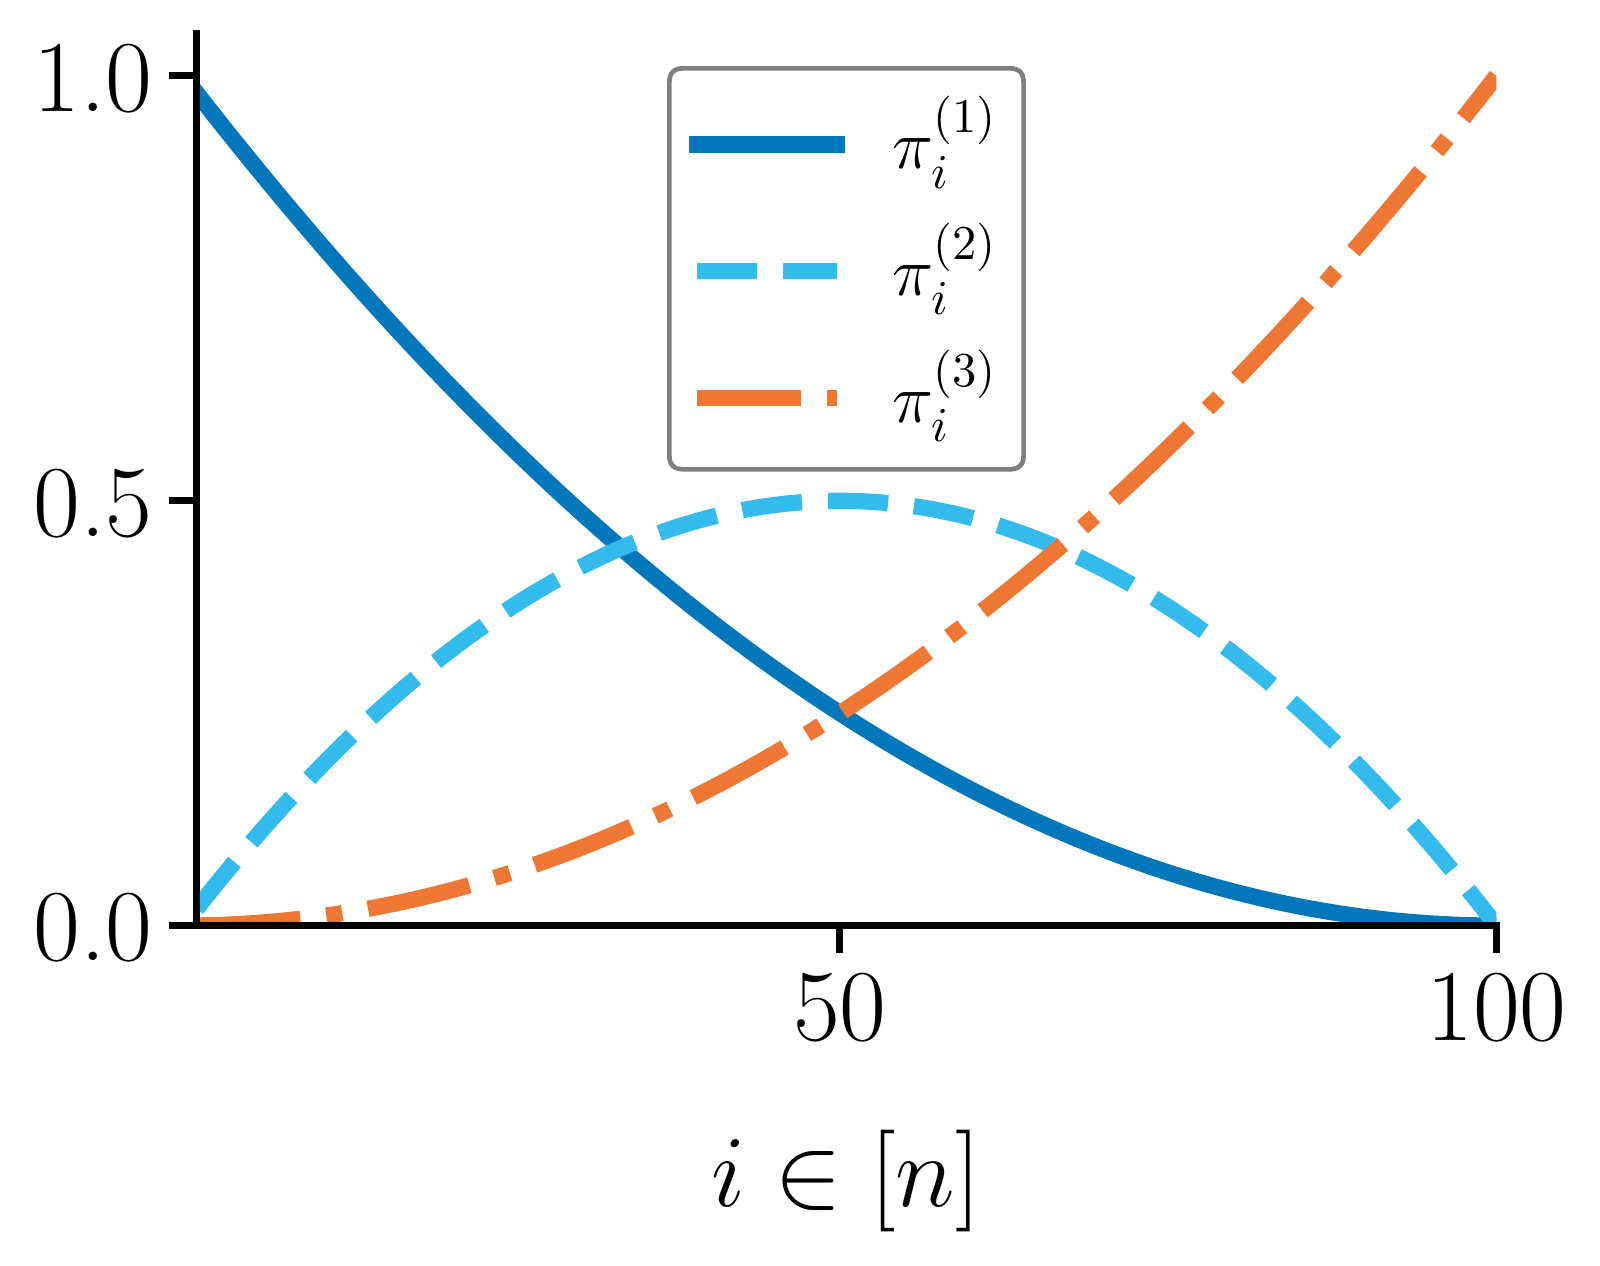

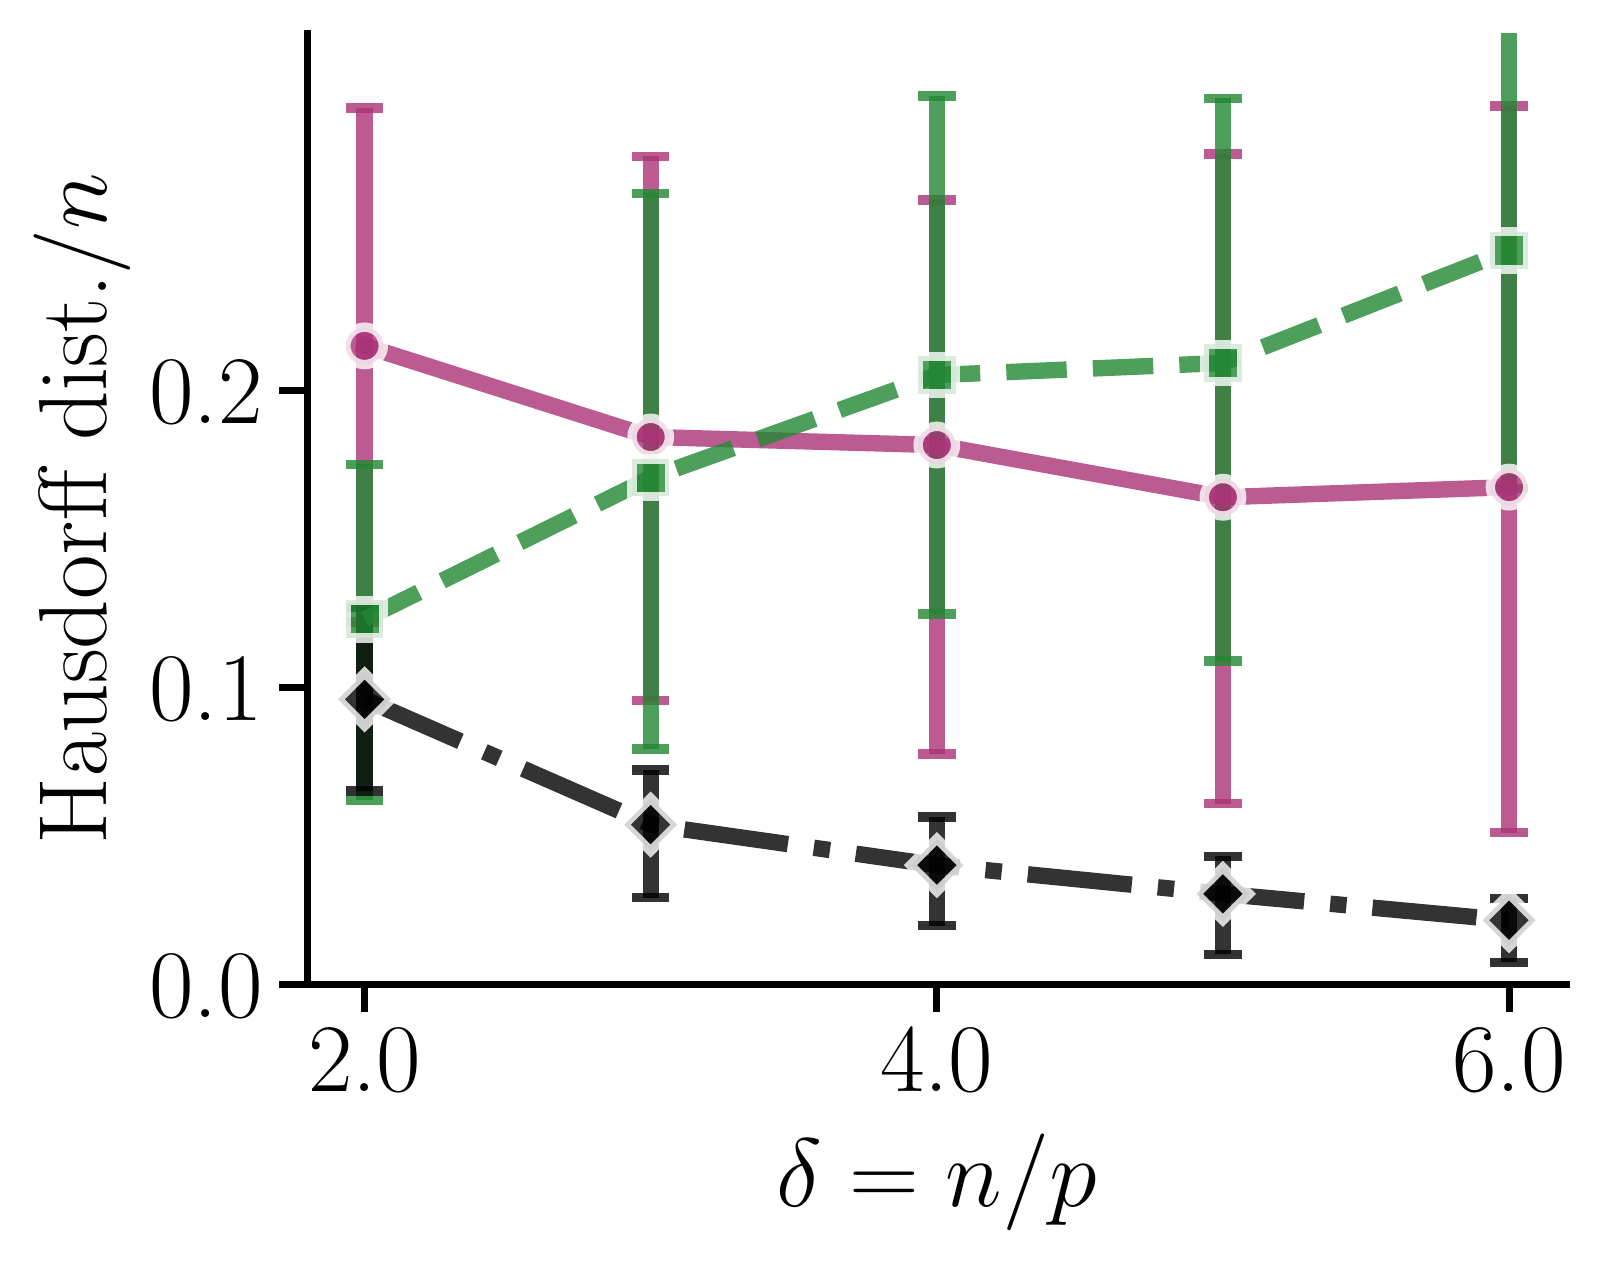

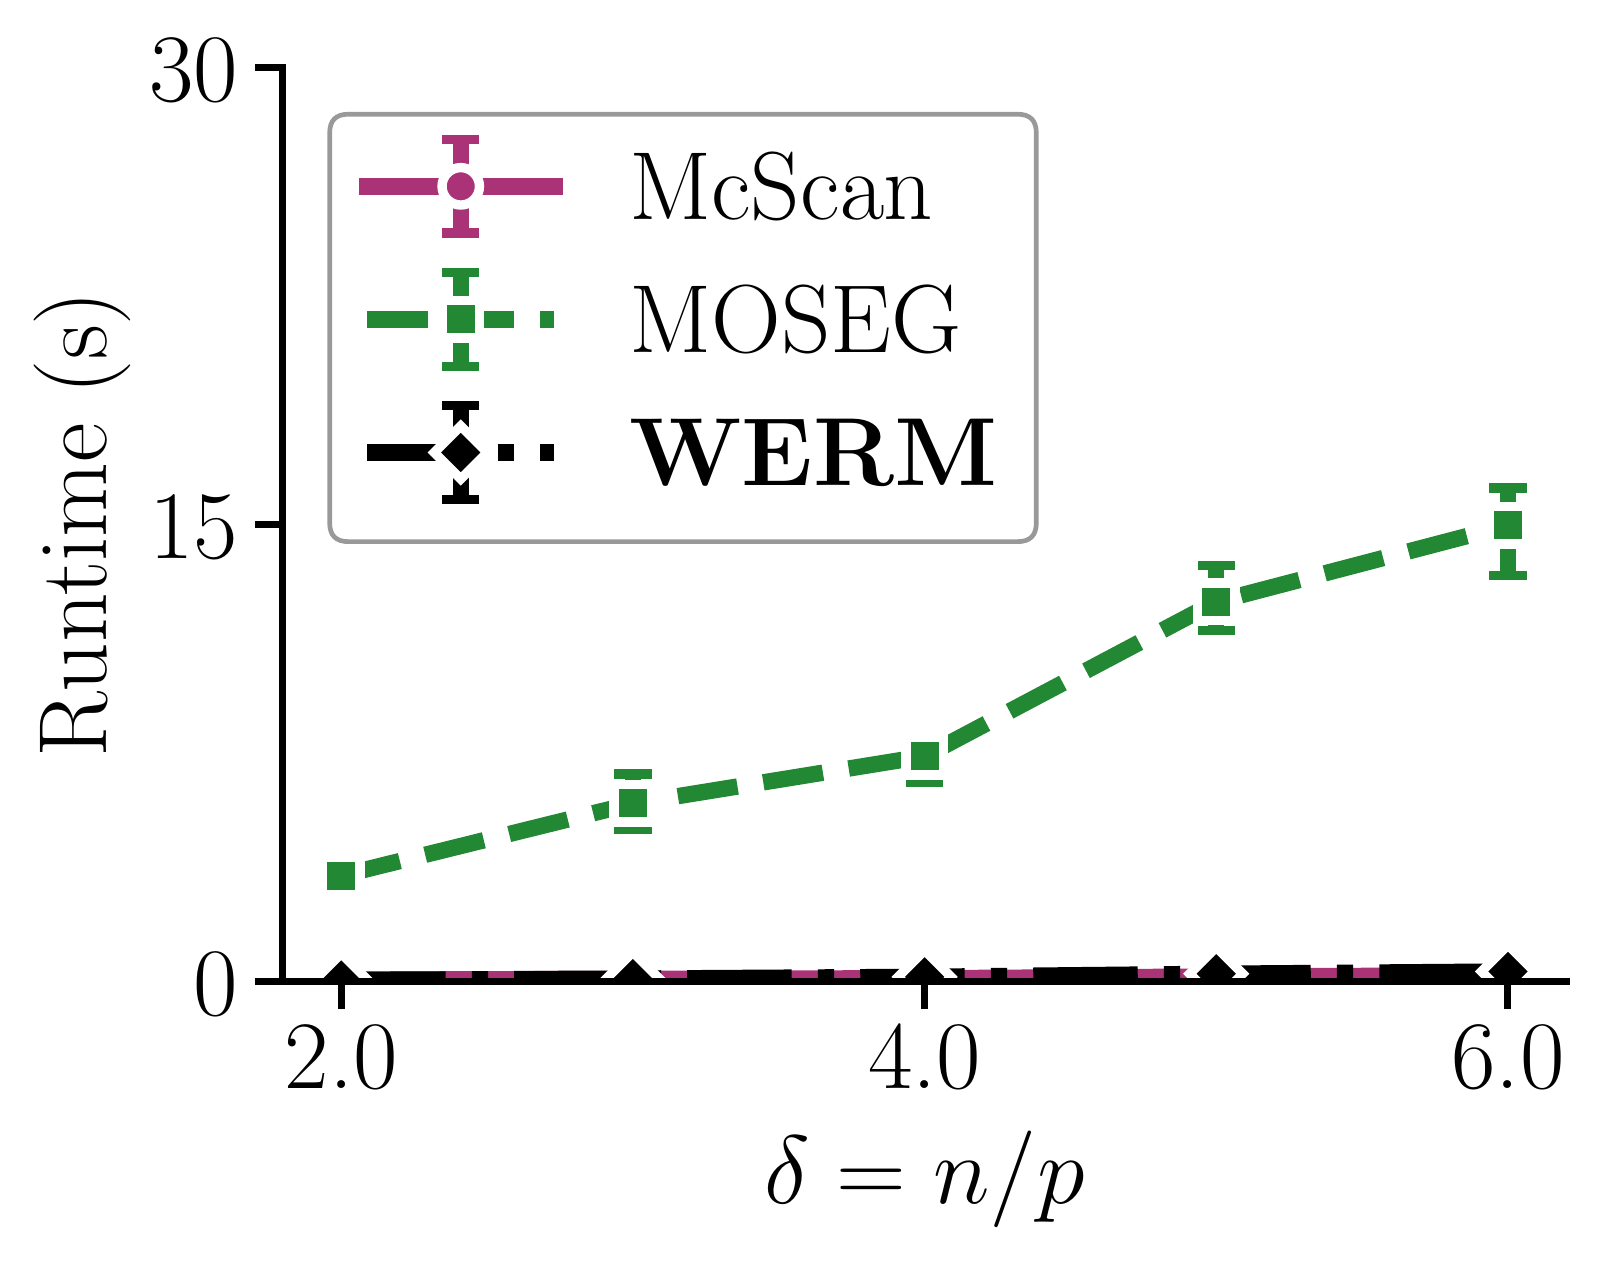

In [5]:
panels = ['figures/marginal_viz_L3_unif_Lub.pdf', 'figures/M1a_location.pdf', 'figures/M1a_runtime.pdf'] if REGENERATE_FIGURES else ['figures/figure_01/panel_01.pdf', 'figures/figure_01/panel_02.pdf', 'figures/figure_01/panel_03.pdf']
show_panels(panels)
